## HPP: DeepSeek-MoE-16B-Base

28 layers (layer 0 DENSE) 64 routed experts, top-6, +2 shared (immutable) D=1408, d=2048 MoEGate returns (idx, w)

**Hierarchy:** `total budget -> layer budgets (ALPHA) -> dynamic expert drop (gamma floors) -> survivor widths (BETA) -> channels`

| symbol | role |
|---|---|
| `gamma` | per-expert energy-retention threshold sets each expert's channel FLOOR |
| `alpha` | LAYER allocation exponent (depth-aware budget split) |
| `beta`  | EXPERT allocation exponent (saliency-weighted survivor widths) |

Special cases recovered: high gamma causes REAP (drop whole experts); low gamma + beta = 0 results to Uniform Slim.

All logic lives in the `hpp` package, this notebook only chooses knobs and calls runners. Every step is cached and resumable.

### 1: Setup

`CUDA_VISIBLE_DEVICES` must be set before torch is imported, which is why it cannot live inside the config.

In [1]:
import os
import sys
from pathlib import Path

GPU_ID = "0"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID

root = Path.cwd()
if not (root / "hpp").exists() and (root.parent / "hpp").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))


from env import configure_hf_cache
configure_hf_cache()

from hpp.models import build
from hpp import runners, gamma as gamma_mod, reconstruction
from hpp.floors import gamma_to_floors
from hpp.plots.saliency import plot_floors
from hpp.plots.pca import pca_functional_subspace
from hpp.plots.comparison import plot_all, plot_task_bars, compare_precisions
from hpp.results import before_after_table

cfg, adapter = build("deepseekmoe16b", quantize=False)
print(cfg.model_tag, cfg.prec_tag, "| sparsities", cfg.sparsities,
      "| recon", cfg.recon.sparsities)
print("results ->", cfg.res_dir)

deepseekmoe16b_chat bf16 | sparsities (0.25, 0.5, 0.75) | recon (0.75,)
results -> results_deepseek_chat_bf16


### 2: profile to, scores to, diagnostics

One forward pass over the packed calibration set fills every statistic the three saliency levels need. Cached per (model, precision, calibration shape); the GPU is freed before returning.

Emits: layer-importance bars (ALPHA driver), expert-saliency heatmap (BETA driver), REAP-saliency heatmap (the baseline's own scoring), and the three convergence panels.

cache hit (scores + profile) [bf16]
  [guard] 0 experts below the activation floor, 0 leak (must be 0)


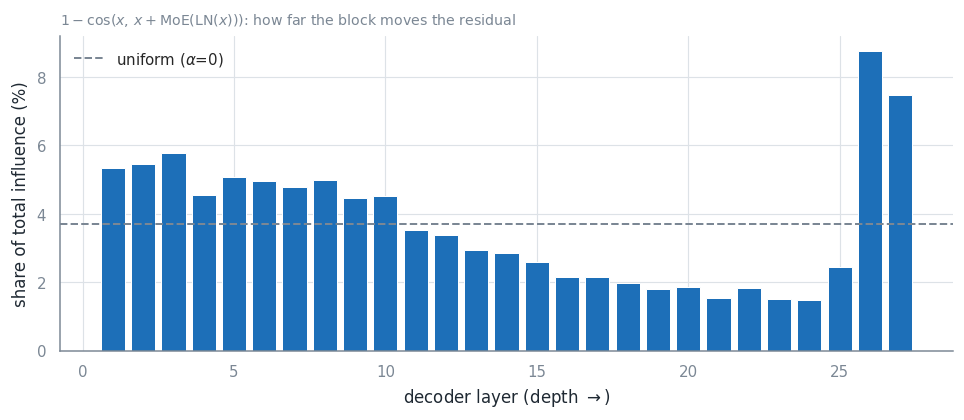

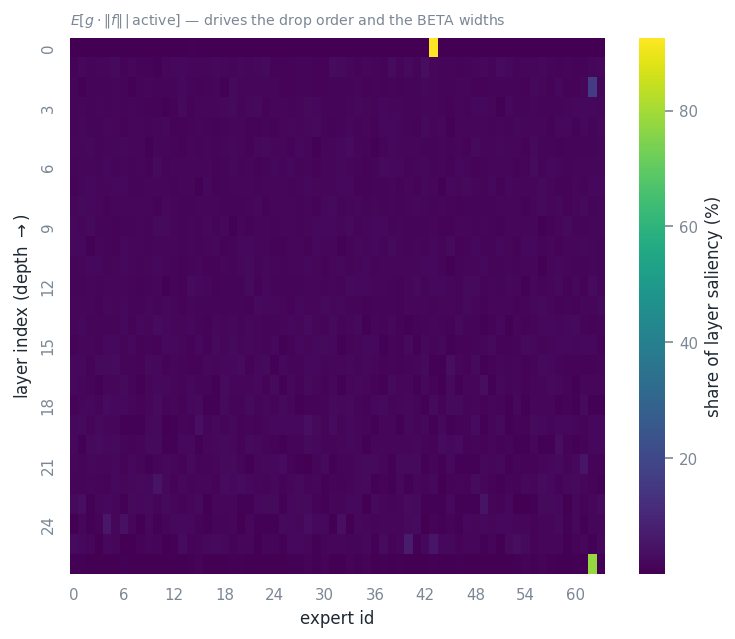

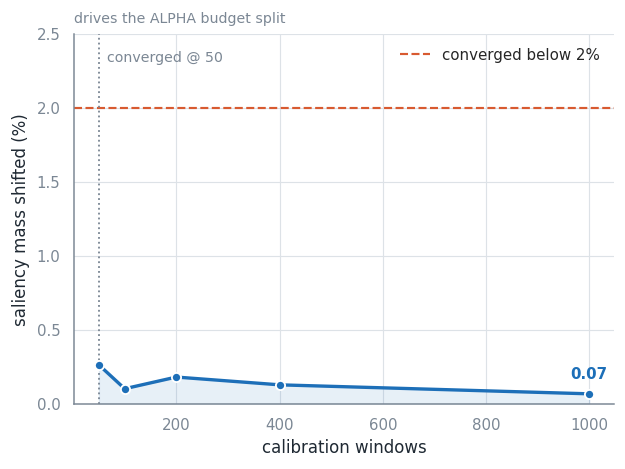

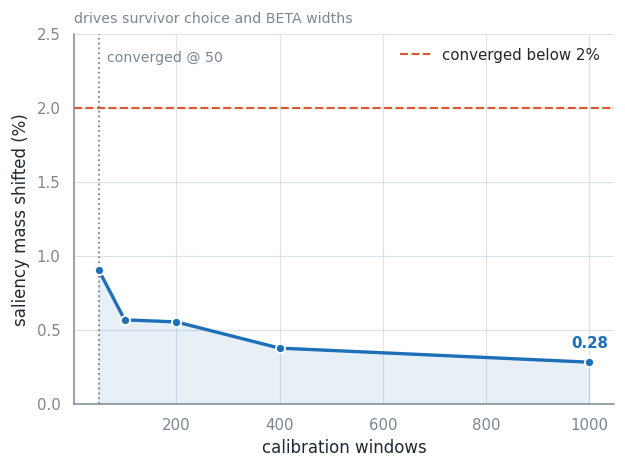

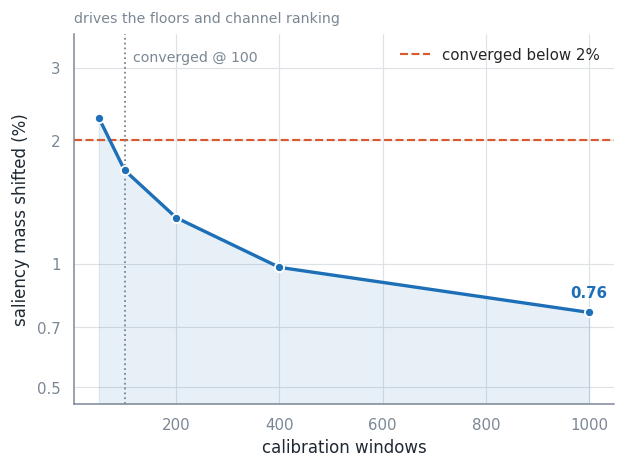

In [2]:
scores, prof = runners.setup(cfg, adapter)

### 3: calibrate gamma

gamma is **read off the model**, not chosen: probe the whole-expert cliff on GPU to find how many experts this model actually tolerates (m*), then pick the gamma whose floors reproduce m* offline. Skip by setting `cfg.gamma = <value>` directly.

  answer key @ s=50%: best perplexity=7.5703 (lower is better), threshold=8.4114 -> 48 survivors (drop 16)
  -> calibrated gamma = 0.838 (mean floor 67.1% of D)


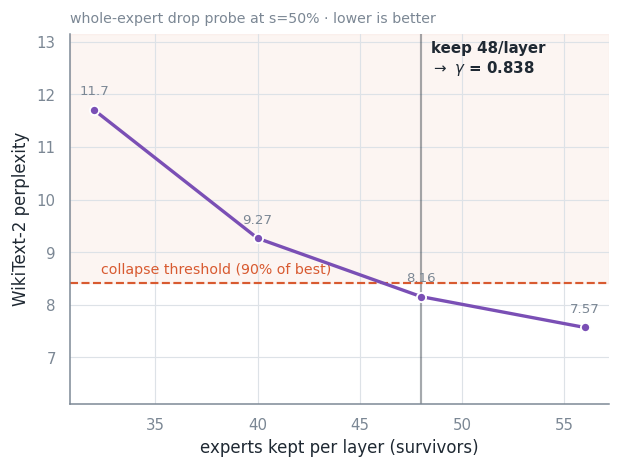

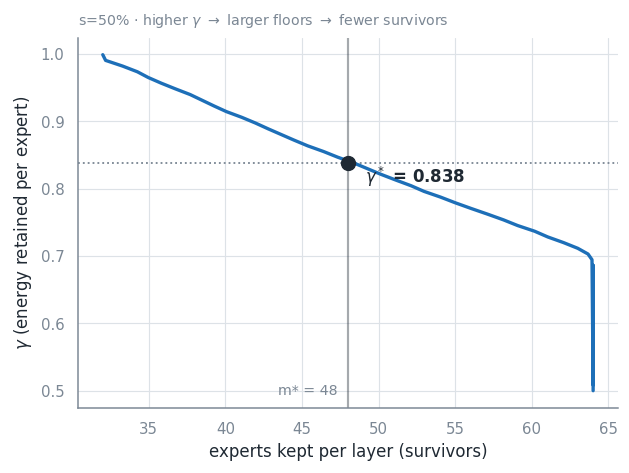

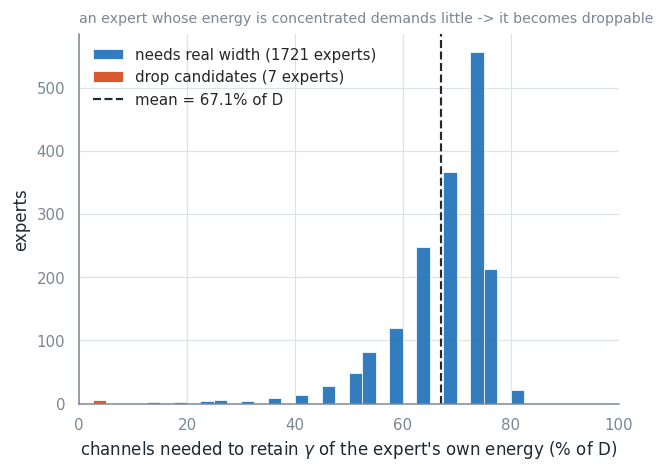

gamma = 0.8383050847457627


In [3]:
if cfg.gamma is None:
    gamma_mod.ensure_drop_keys(cfg, adapter, scores)
    cfg.gamma, curve = gamma_mod.calibrate_gamma(cfg, scores)

plot_floors(cfg, gamma_to_floors(cfg, scores, cfg.gamma), cfg.gamma)
print("gamma =", cfg.gamma)

### 4: functional subspace (REAP Fig. 1 analogue)

Does the surviving set still span the original experts' output space? One PCA per layer, three panels sharing coordinates: Original / REAP / HPP.

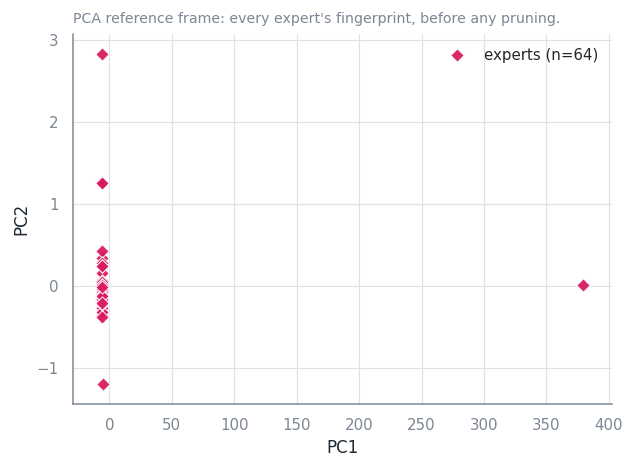

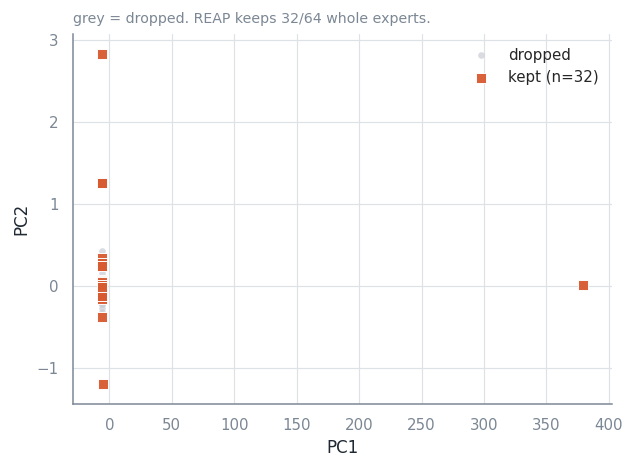

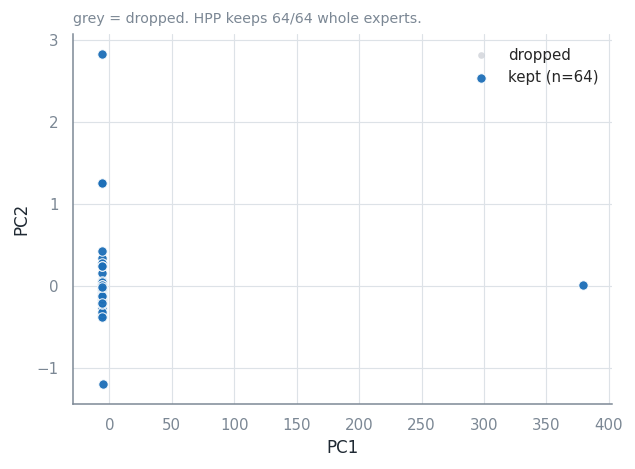

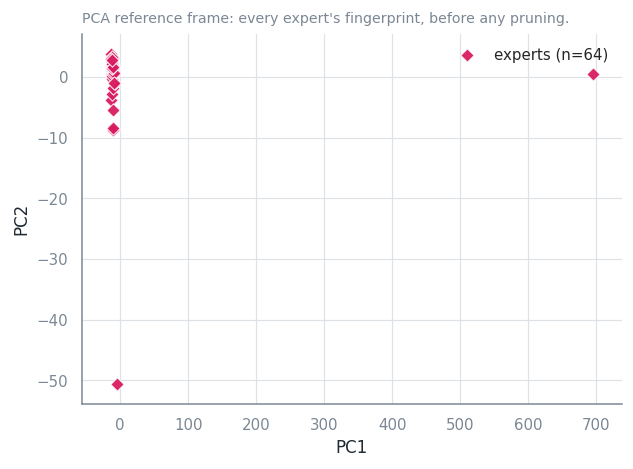

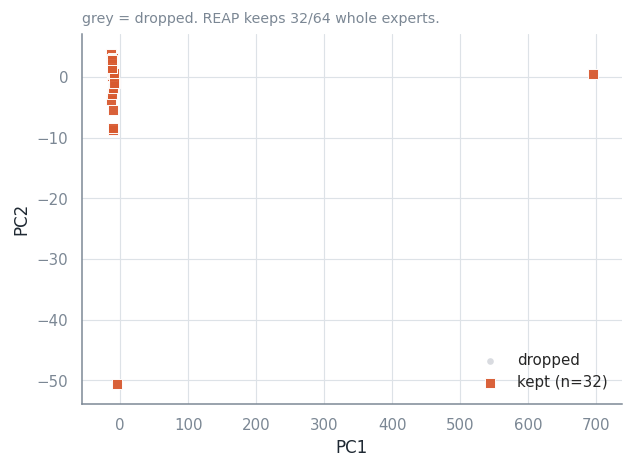

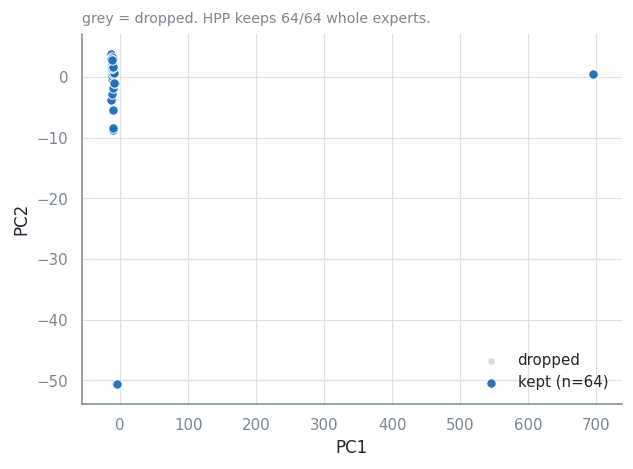


  PC1+PC2 cumulative variance explained (cf. REAP Table A4):
 layer_id  evr_original  evr_reap  evr_hpp  reap_survivors  hpp_survivors
        1        0.9990    0.9994   0.9990              32             64
       27        0.9808    0.9842   0.9808              32             64


,layer_id,evr_original,evr_reap,evr_hpp,reap_survivors,hpp_survivors
0,1,0.9990,0.9994,0.9990,32,64
1,27,0.9808,0.9842,0.9808,32,64


In [4]:
pca_functional_subspace(cfg, scores, sparsity=0.50)

### 5: baseline + sweep

Every sparsity point goes through `run_hpp`/`run_reap`, so each one leaves its allocation CSV, pruned-index NPZ and kept-capacity heatmap behind.

In [5]:
PROFILE = "fast_sweep"   

runners.run_baseline(cfg, adapter, PROFILE)

  [skip] baseline



SWEEP [bf16] deepseekmoe16b_chat: alpha=1.0 beta=1.0 gamma=0.838 profile=fast_sweep
  [skip] HPP s=25% a=1.0 b=1.0
  [skip] REAP s=25%
  [skip] HPP s=50% a=1.0 b=1.0
  [skip] REAP s=50%
  [skip] HPP s=75% a=1.0 b=1.0
  [skip] REAP s=75%


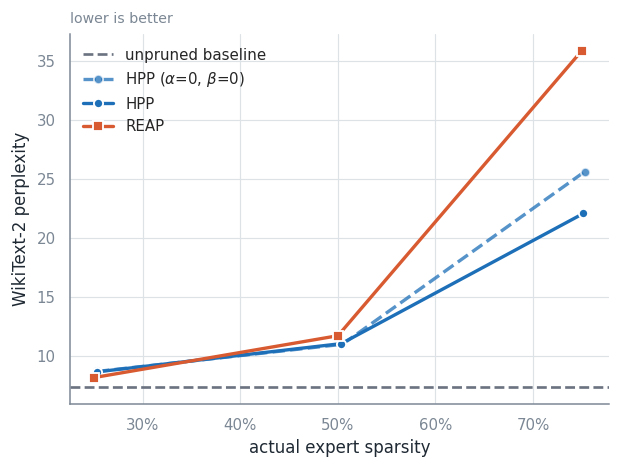

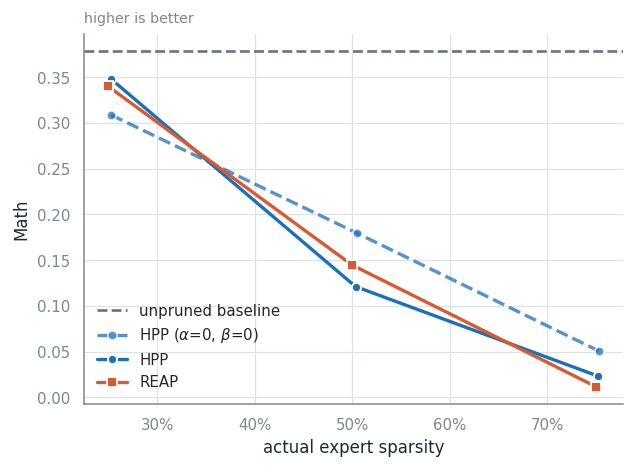

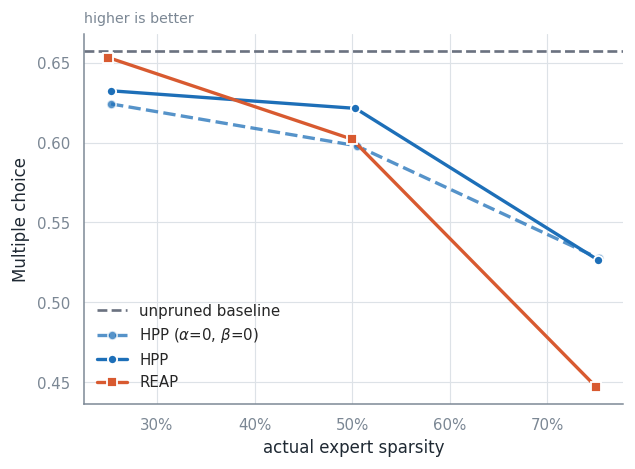

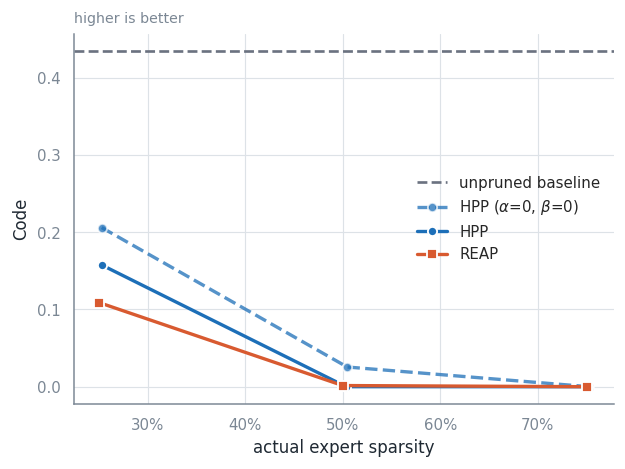

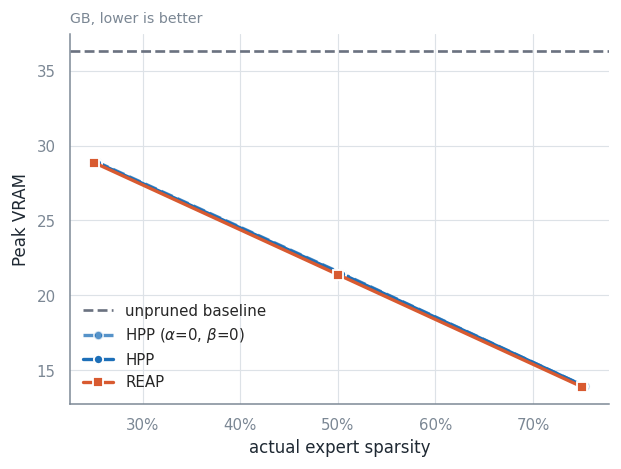

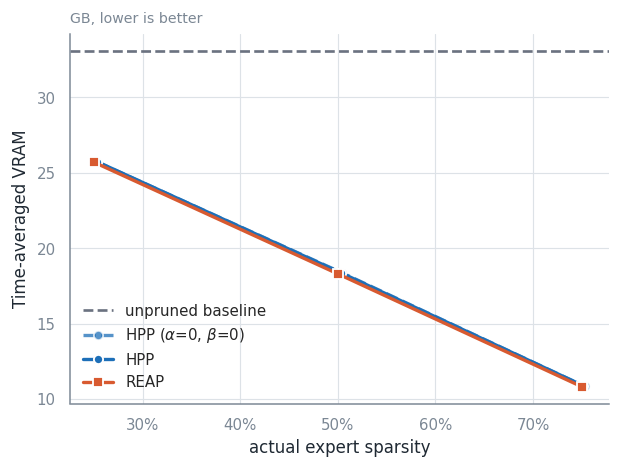

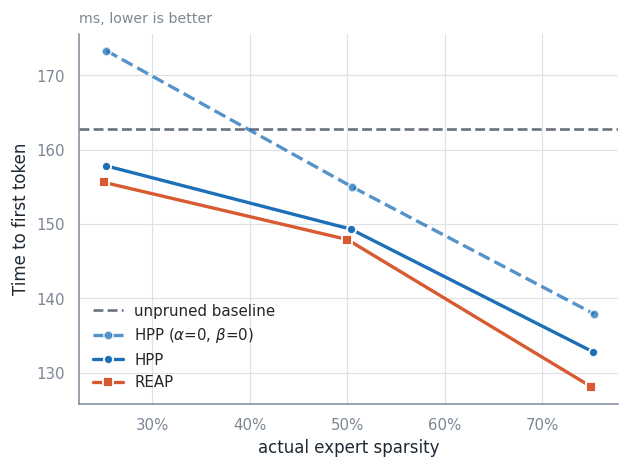

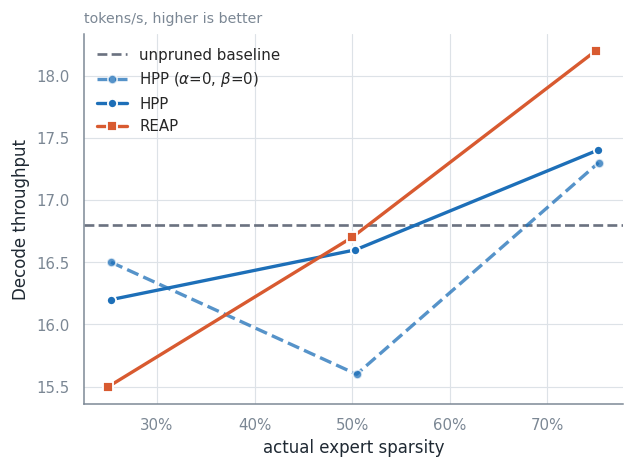

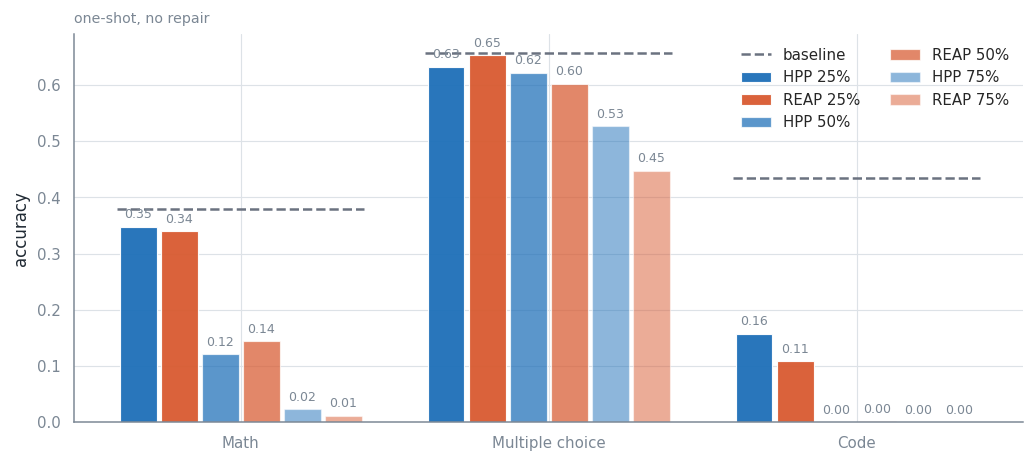

In [6]:
runners.run_sweep(cfg, adapter, scores, profile=PROFILE)

#### Ablation: uniform allocation (alpha = beta = 0)

Isolates what the depth-aware and saliency-weighted allocation actually buy over spending the same budget uniformly.


SWEEP [bf16] deepseekmoe16b_chat: alpha=0.0 beta=0.0 gamma=0.838 profile=fast_sweep
  [skip] HPP s=25% a=0.0 b=0.0
  [skip] REAP s=25%
  [skip] HPP s=50% a=0.0 b=0.0
  [skip] REAP s=50%
  [skip] HPP s=75% a=0.0 b=0.0
  [skip] REAP s=75%


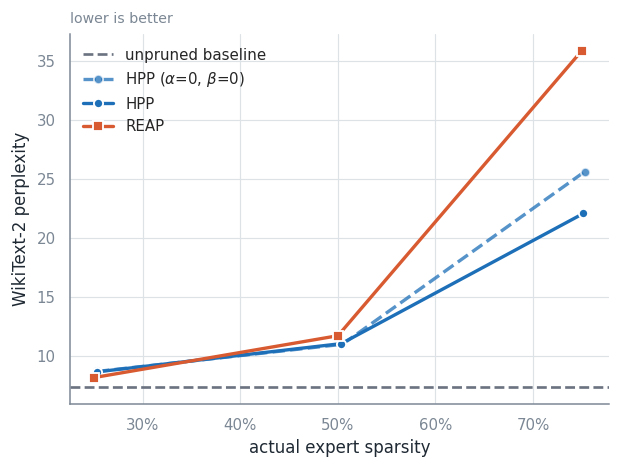

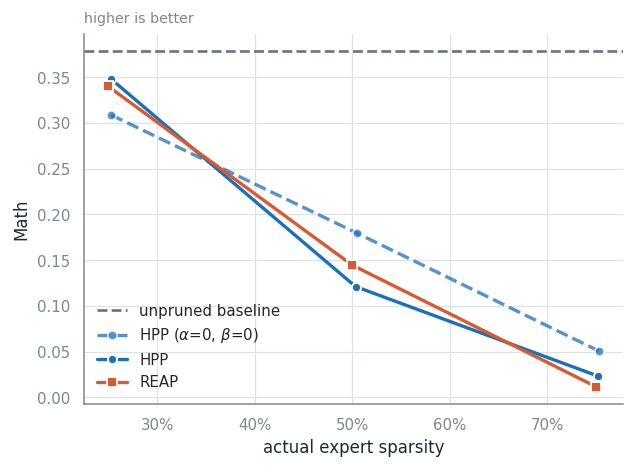

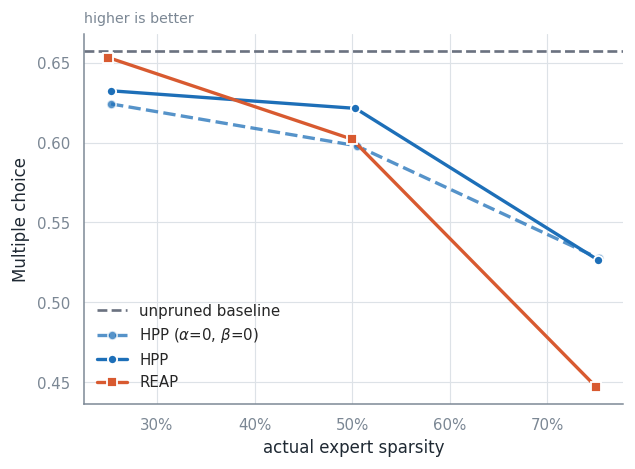

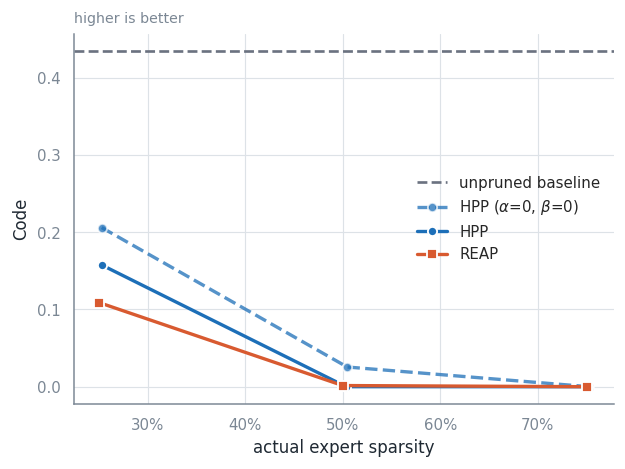

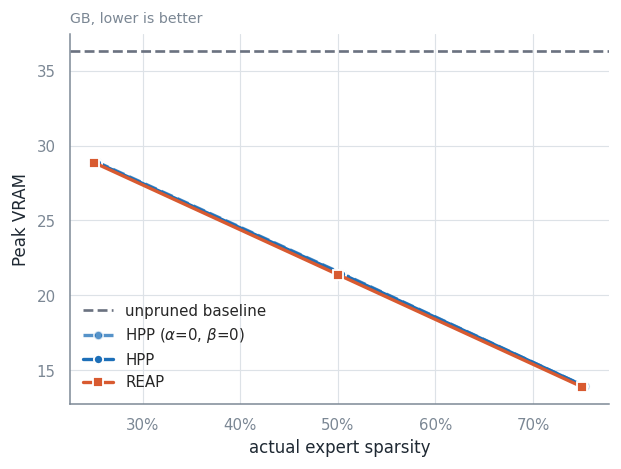

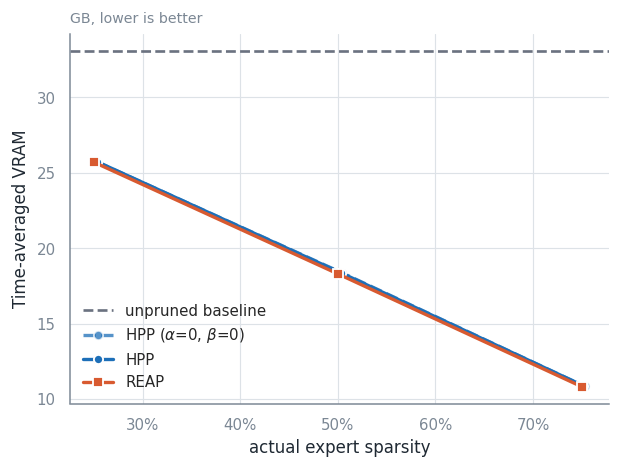

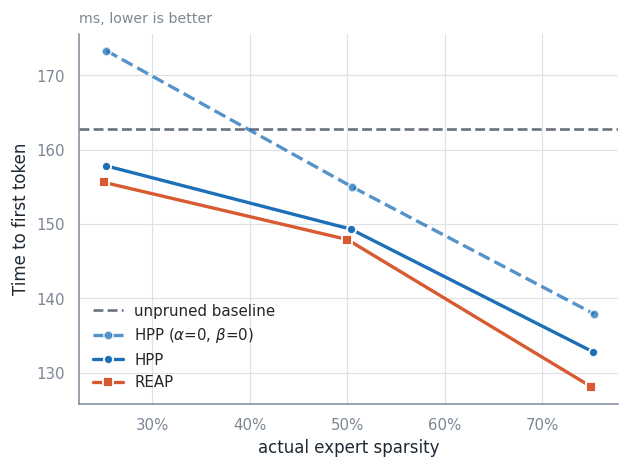

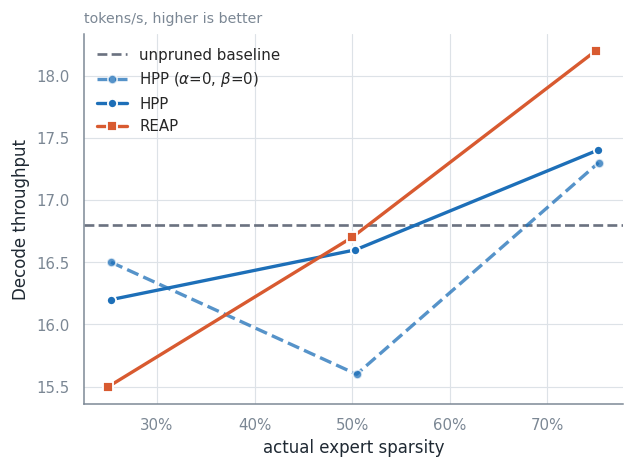

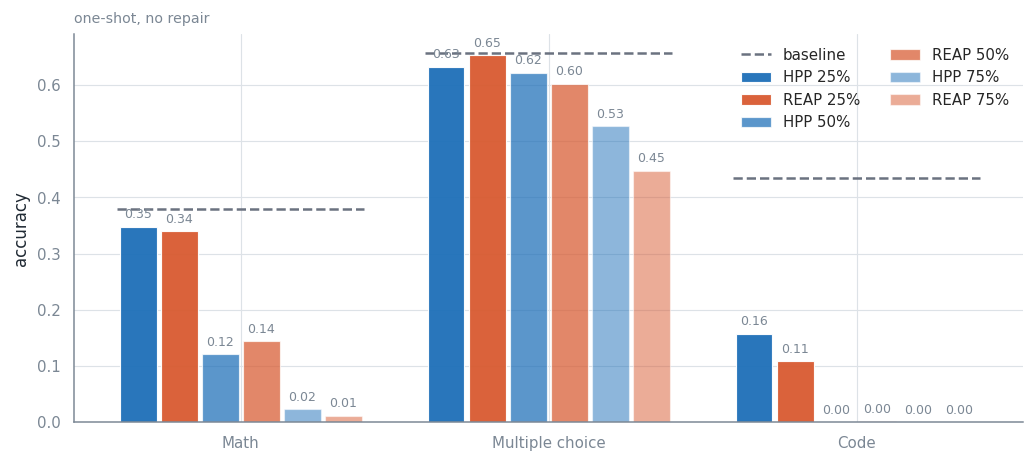

In [7]:
runners.run_sweep(cfg, adapter, scores, alpha=0.0, beta=0.0, profile=PROFILE)

### 6: LoRA reconstruction (C4)

Does HPP's channel selection leave more *repairable* structure than REAP's whole-expert selection? LoRA on surviving experts' gate/up/down only; router and attention frozen. Identical seed, data order and schedule for both methods.

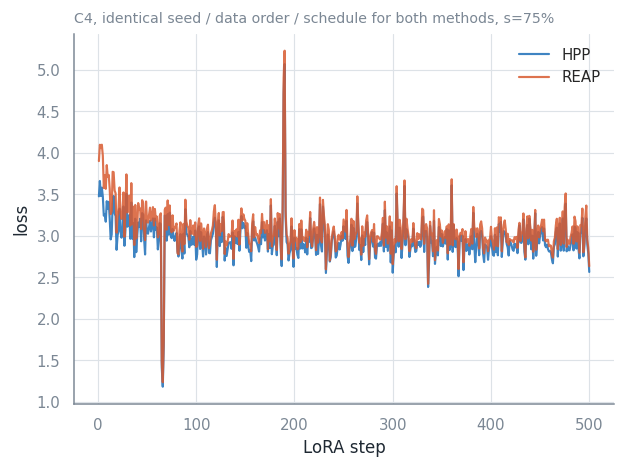

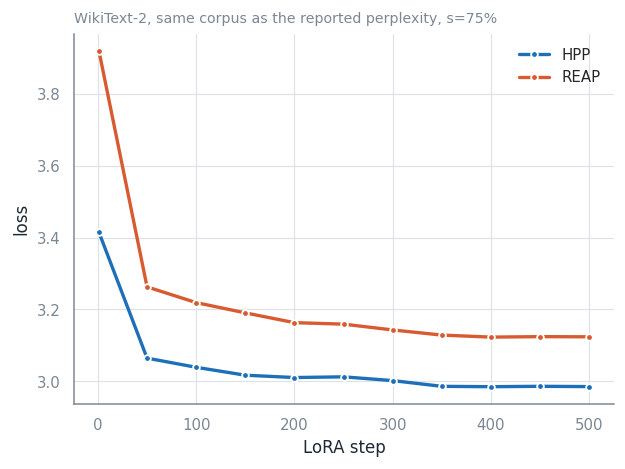

  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [skip] repaired hpp s=75% already logged
  [skip] repaired reap s=75% already logged
Method Sparsity  perplexity (before)  perplexity (after)  recovered %
   HPP    75.2%              22.0756             13.6287         38.3
  REAP    75.0%              35.8757             15.5759         56.6


,Method,Sparsity,perplexity (before),perplexity (after),recovered %
0,HPP,75.2%,22.0756,13.6287,38.3
1,REAP,75.0%,35.8757,15.5759,56.6


In [8]:
reconstruction.run_all_reconstructions(cfg, adapter, scores)

for s in cfg.recon.sparsities:
    for m in ("hpp", "reap"):
        reconstruction.evaluate_repaired(cfg, adapter, scores, m, s)

before_after_table(cfg, PROFILE, "perplexity")

### 7: Ablation Studies: math-only calibration (HPP vs REAP)

REAP reports that calibrating on a domain skews the pruned model heavily toward that domain's evaluations. This checks that on this pipeline: build calibration windows from GSM8K + MATH train only (no round-robin with the other domains), score the model on that, then prune with the same `select_hpp`/`reap_keep` the main sweep uses and evaluate on GSM8K/MATH-500 at the same sparsity grid.

  cache hit (math-calib scores) [bf16]
  [skip] math-calib hpp s=25% already logged
  [skip] math-calib reap s=25% already logged
  [skip] math-calib hpp s=50% already logged
  [skip] math-calib reap s=50% already logged
  [skip] math-calib hpp s=75% already logged
  [skip] math-calib reap s=75% already logged
method  sparsity  actual_sparsity  perplexity  gsm8k  math500  math_avg  peak_vram_gb  avg_vram_gb  ttft_ms  decode_tps
   hpp      0.25         0.251552      9.5192 0.5625   0.1641   0.36330         27.51        25.65    153.9        16.6
  reap      0.25         0.250000      9.8569 0.6094   0.1641   0.38675         27.48        25.60    154.9        15.9
   hpp      0.50         0.503341     14.4391 0.3984   0.1172   0.25780         20.07        18.23    151.6        16.9
  reap      0.50         0.500000     17.3715 0.5625   0.1562   0.35935         20.01        18.15    143.9        16.8
   hpp      0.75         0.752446     36.3752 0.0703   0.0469   0.05860         12.60   

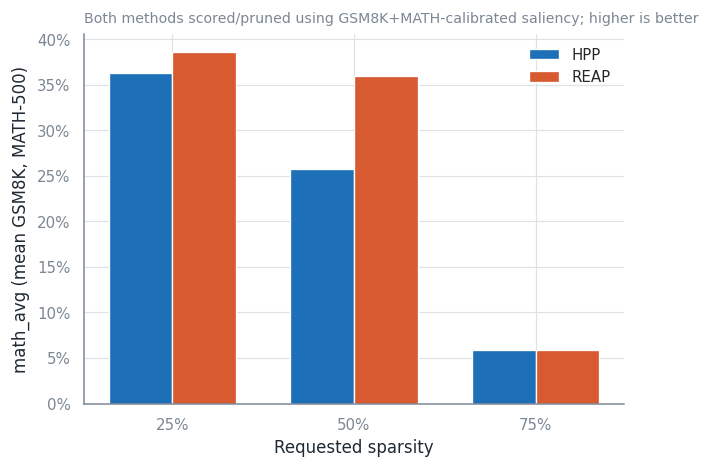

In [9]:
from hpp import ablation

math_calib_df = ablation.run_math_calib_ablation(cfg, adapter, sparsities=cfg.sparsities)

### Does the mixed-domain calibration actually generalise?

If domain calibration matters the way REAP describes, pruning on math-only saliency should trade away general capability for math capability. Re-prune at `sparsity=0.25` using the SAME math-only scores as above, but evaluate with the FULL battery (MC + math + code) the main sweep used, then diff against the row already logged in `sweep.csv` for that method/sparsity under the default mixed-domain calibration. If mixed-domain calibration generalises, `mc_avg`/`code_avg` here should read noticeably lower than the mixed-domain row; if it doesn't collapse, the multi-domain mix is doing its job.

  [WARNING] 2 rows match hpp s=25% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  cache hit (math-calib scores) [bf16]
  [skip] math-calib generalization hpp s=25% already logged
  [skip] math-calib generalization reap s=25% already logged

  mixed-domain calibration (sweep.csv, profile=full_sweep) vs math-only calibration @ s=25%:
  [WARNING] 2 rows match hpp s=25% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  HPP   perplexity: mixed=8.6394 math=9.4896 COLLAPSED | mc_avg: mixed=0.6324 math=0.6273 COLLAPSED | math_avg: mixed=0.3477 math=0.3330 COLLAPSED | code_avg: mixed=0.1575 math=0.2795
  REAP  perplexity: mixed=8.1560 math=9.8777 COLLAPSED | mc_avg: mixed=0.6532 math=0.6236 COLLAPSED | math_avg: mixed=0.3398 math=0.3700 | code_avg: mixed=0.1090 math=0.3690
  [WARNING] 2 rows match hpp s=25% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first


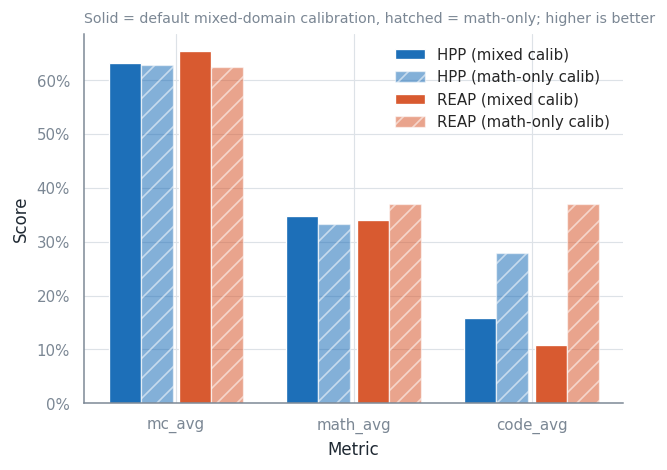

In [10]:
gen_df = ablation.evaluate_math_calib_generalization(cfg, adapter, sparsity=0.25)

### Does a math-trained reconstruction recover math accuracy and does HPP still repair better?

The C4 reconstruction above (cell 15) trains on generic prose, which is why gsm8k/math500 land near zero for both methods after repair there's no reasoning signal in that training data at all. This repeats the SAME reconstruction (same mixed-domain pruning, same LoRA rank/steps/schedule) but trains on chat-formatted, prompt-masked word-problem examples from `microsoft/orca-math-word-problems-200k` instead of C4. That corpus is independent of GSM8K/MATH-500's own train/test split by construction, so gsm8k/math500 stay genuinely held-out, training on a benchmark's own train split before scoring its test split.

Runs at `cfg.recon.sparsities[0]` (0.75), matching the existing reconstruction study's scope. Saves under `mathrecon` filenames and logs to `ablation_math_reconstruction.csv`, the existing C4-trained LoRA adapters and `sweep_reconstructed.csv` are saved separately.

  [skip] math-recon training hpp s=50% already done (lora_mathrecon_hpp_s50_deepseekmoe16b_chat.pt exists)
  [WARNING] 2 rows match hpp s=50% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [skip] math-recon eval hpp s=50% already logged
  [skip] math-recon training reap s=50% already done (lora_mathrecon_reap_s50_deepseekmoe16b_chat.pt exists)
  [skip] math-recon eval reap s=50% already logged
  [WARNING] 2 rows match hpp s=50% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [WARNING] 2 rows match hpp s=50% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first


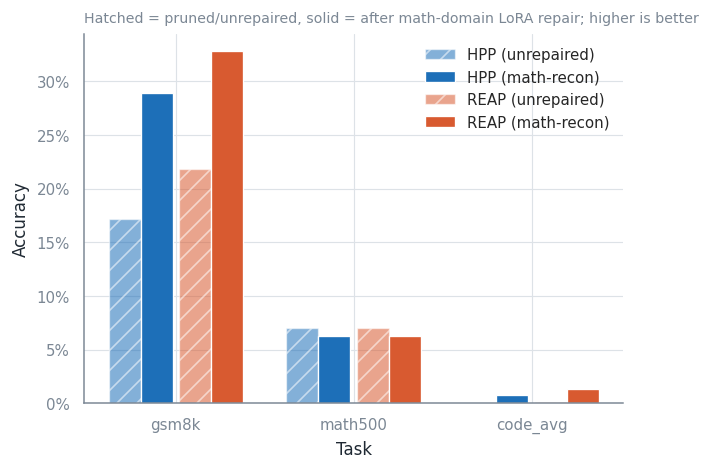

In [11]:
math_recon_df = ablation.run_math_reconstruction_ablation(cfg, adapter, scores, sparsity=(0.50))